#Import

In [ ]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_graphviz
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score
import graphviz
import pydot
from sklearn.preprocessing import StandardScaler

#Load DataSet

In [ ]:
iris = datasets.load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)


#Supervised Learning

Supervised learning is a type of machine learning where the model is trained using labeled data, meaning each input comes with a known output. The algorithm learns to map inputs to their correct outputs by finding patterns in the data, allowing it to make predictions on new, unseen examples. For instance, it can learn to classify emails as spam or not spam, or predict house prices based on features like size and location. In short, supervised learning teaches a model by example so it can generalize and make accurate predictions in the future.

## Linear Regression

Linear regression is a supervised learning algorithm used to model the relationship between one or more input variables (called independent variables) and an output variable (called the dependent variable) by fitting a straight line through the data. The goal is to find the line that best predicts the output based on the inputs

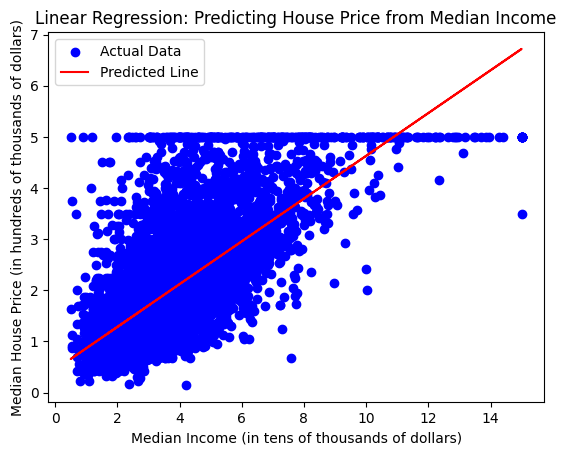

In [ ]:
X_boston, y_boston = datasets.fetch_california_housing(return_X_y=True)
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(X_boston, y_boston, test_size=0.3, random_state=42)
linear_regressor = LinearRegression() # Train the Linear Regression
linear_regressor.fit(X_train_b[:, :1], y_train_b) # Train the Linear Regression
y_pred_b = linear_regressor.predict(X_test_b[:, :1]) # Make predictions

# Visualization
plt.scatter(X_test_b[:, 0], y_test_b, color='blue', label="Actual Data")
plt.plot(X_test_b[:, 0], y_pred_b, color='red', label="Predicted Line")
plt.title("Linear Regression: Predicting House Price from Median Income")
plt.xlabel("Median Income (in tens of thousands of dollars)")
plt.ylabel("Median House Price (in hundreds of thousands of dollars)")
plt.legend()
plt.show()


##Logistic Regression

Logistic regression is a supervised learning algorithm used for classification tasks, meaning it predicts which category or class a data point belongs to. Instead of fitting a straight line like linear regression, it uses a sigmoid (S-shaped) function to output probabilities between 0 and 1.

In [ ]:

# Load the Iris dataset
iris = datasets.load_iris()
X = iris.data
y = iris.target

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

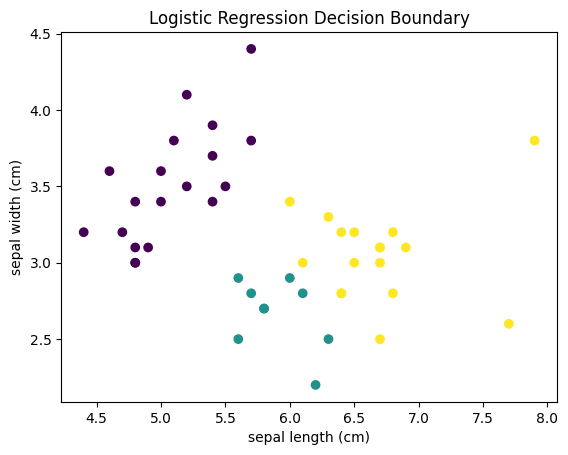

In [ ]:


# Train the Logistic Regression model
log_regressor = LogisticRegression(max_iter=200)
log_regressor.fit(X_train[:, :2], y_train)  # using only the first two features

# Make predictions
y_pred = log_regressor.predict(X_test[:, :2])

# Visualization
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_pred, cmap='viridis')
plt.title("Logistic Regression Decision Boundary")
plt.xlabel(iris.feature_names[0])  # sepal length
plt.ylabel(iris.feature_names[1])  # sepal width
plt.show()

##Decision Tree

A decision tree works by splitting data into smaller and smaller groups based on feature values to make predictions. It’s like a flowchart made of nodes (questions) and branches (answers).
At each node, the algorithm chooses the feature and threshold that best separates the data into groups that are as pure as possible — meaning most samples in each group belong to the same class.

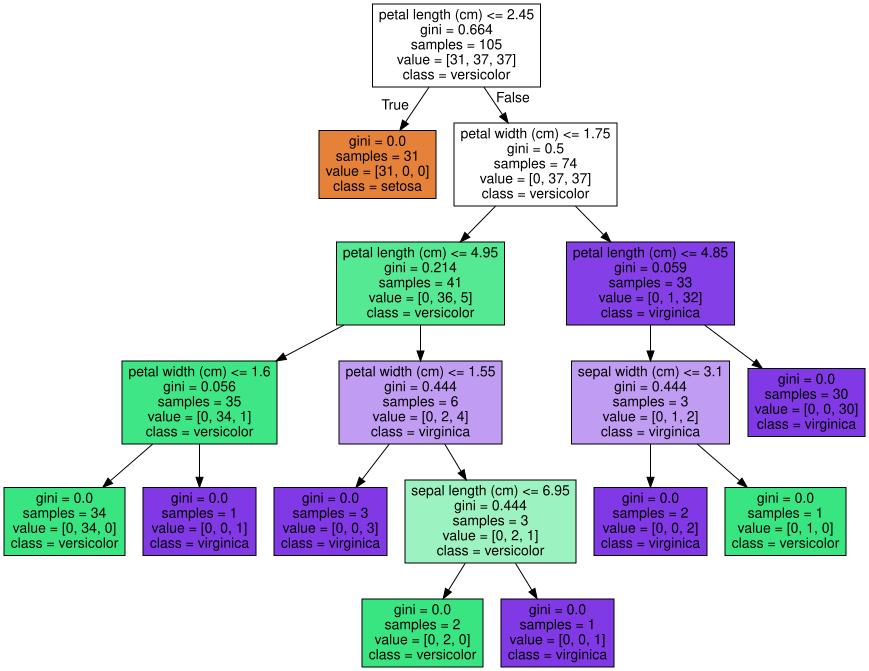

In [ ]:
tree = DecisionTreeClassifier() # Train the Decision Tree
tree.fit(X_train, y_train)  # Train the Decision Tree
y_pred = tree.predict(X_test) # Make predictions

# Visualization of decision tree
dot_data = export_graphviz(tree, out_file=None, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
graph = graphviz.Source(dot_data)
graph.render("iris_decision_tree", format="png")
graph

##Random Forest

A Random Forest is an advanced machine learning algorithm that combines many decision trees to make more accurate and stable predictions. It’s called an “ensemble” method because it merges the results of multiple models.

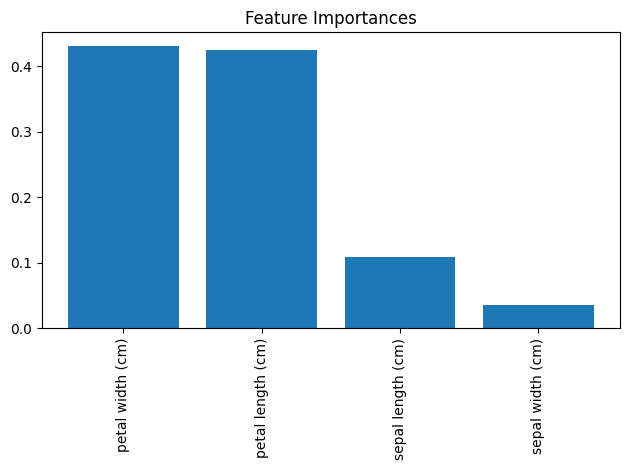

In [ ]:
forest = RandomForestClassifier() # Train the Random Forest
forest.fit(X_train, y_train) # Train the Random Forest

# Visualization of feature importance
importances = forest.feature_importances_
indices = np.argsort(importances)[::-1]
plt.title("Feature Importances")
plt.bar(range(X_train.shape[1]), importances[indices], align='center')
plt.xticks(range(X_train.shape[1]), np.array(iris.feature_names)[indices], rotation=90)
plt.tight_layout()
plt.show()

##Supervector Machine

A Support Vector Machine (SVM) is a supervised learning algorithm used for classification and sometimes regression. It works by finding the best boundary (called a hyperplane) that separates data points of different classes in a feature space.
The goal of SVM is to maximize the margin, which is the distance between the hyperplane and the nearest data points from each class (called support vectors). A larger margin usually means better generalization to new data.

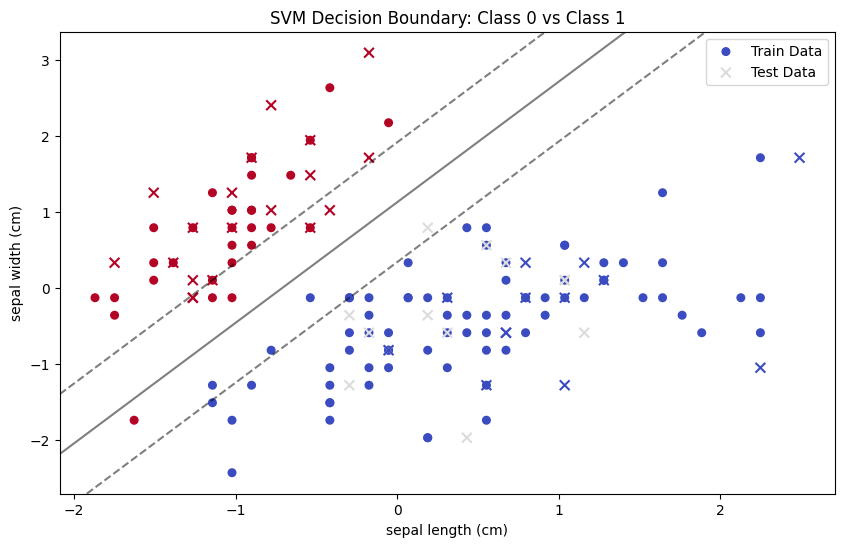

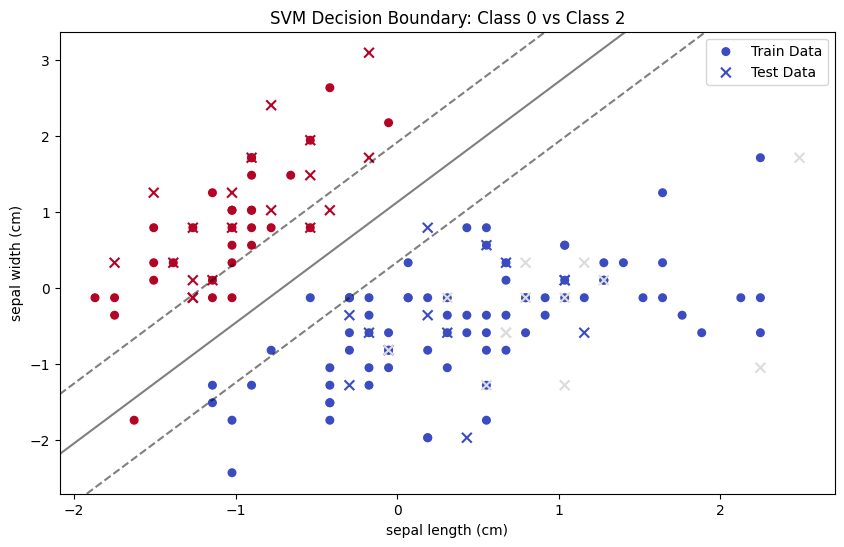

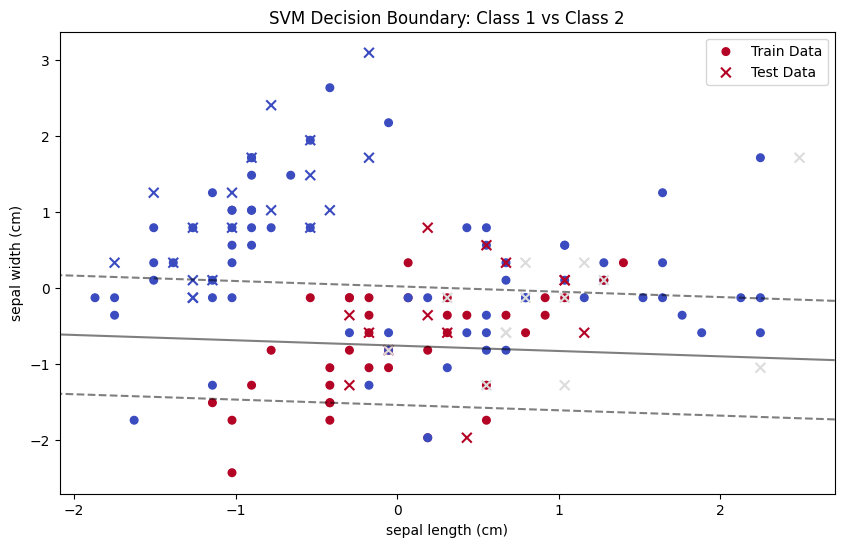

In [ ]:

# Load the Iris dataset
iris = datasets.load_iris()
X2 = iris.data[:, :2]  # Use only the first two features (sepal length and sepal width)
Y2 = iris.target

# Standardize features
scaler = StandardScaler()
X2 = scaler.fit_transform(X2)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X2, Y2, test_size=0.3, random_state=42)

# Train the SVM model for each class pair
def plot_iris_svm(X_train, X_test, y_train, y_test, class1, class2):
    # Create a binary target for the two classes
    y_train_binary = np.where(y_train == class1, 1, -1)
    y_test_binary = np.where(y_test == class1, 1, -1)
    y_test_binary[y_test == class2] = 0

    # Train SVM
    svm = SVC(kernel='linear')
    svm.fit(X_train[y_train_binary != 0], y_train_binary[y_train_binary != 0])  # Train with binary classes

    # Plot decision boundary
    plt.figure(figsize=(10, 6))
    plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train_binary, cmap='coolwarm', s=30, label='Train Data')
    plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test_binary, marker='x', cmap='coolwarm', s=50, label='Test Data')

    ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Create grid to evaluate model
    xx, yy = np.meshgrid(np.linspace(xlim[0], xlim[1], 50),
                         np.linspace(ylim[0], ylim[1], 50))

    # Predict the function value for the whole grid
    Z = svm.decision_function(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Plot the decision boundary and margins
    ax.contour(xx, yy, Z, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])
    plt.title(f"SVM Decision Boundary: Class {class1} vs Class {class2}")
    plt.xlabel(iris.feature_names[0])  # Sepal length
    plt.ylabel(iris.feature_names[1])  # Sepal width
    plt.legend()
    plt.show()

# Plot SVM decision boundaries for each pair of classes
classes = np.unique(Y2)
for i in range(len(classes)):
    for j in range(i + 1, len(classes)):
        plot_iris_svm(X_train, X_test, y_train, y_test, classes[i], classes[j])


##  Neural Network (MLP)

A Neural Network, or Multilayer Perceptron (MLP), is a supervised learning algorithm inspired by how the human brain works. It consists of layers of interconnected nodes called neurons — an input layer, one or more hidden layers, and an output layer.
Each neuron takes inputs, multiplies them by weights, adds a bias, and passes the result through an activation function (like ReLU or sigmoid) to introduce non-linearity. The network learns by adjusting these weights using a process called backpropagation, which minimizes the error between predicted and actual outputs.

In [ ]:

mlp = MLPClassifier(max_iter=1000) # Train the MLP
mlp.fit(X_train, y_train) # Train the MLP

y_pred_mlp = mlp.predict(X_test) #Make Prediction
print("Accuracy (MLP):", accuracy_score(y_test, y_pred_mlp))

Accuracy (MLP): 0.7555555555555555


#  Unsupervised Learning

Unsupervised learning is a type of machine learning where the model is trained on unlabeled data — meaning there are no predefined outputs or target values. The goal is for the algorithm to find hidden patterns or structures within the data on its own.


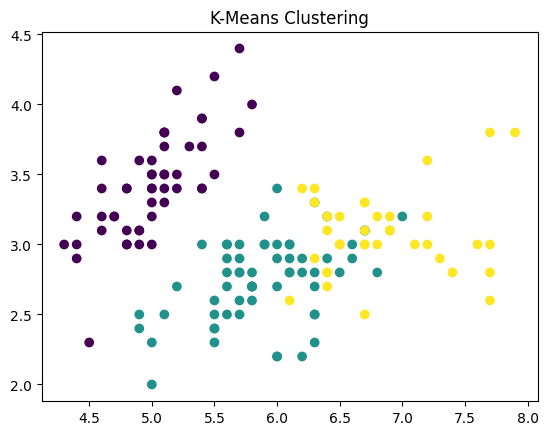

In [ ]:
## a) K-Means Clustering
kmeans = KMeans(n_clusters=3)
kmeans.fit(X)

# Visualization
plt.scatter(X[:, 0], X[:, 1], c=kmeans.labels_, cmap='viridis')
plt.title("K-Means Clustering")
plt.show()

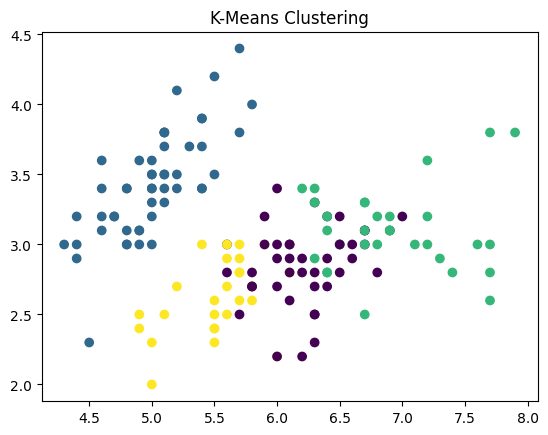

In [ ]:
## a) K-Means Clustering
kmeans = KMeans(n_clusters=4)
kmeans.fit(X)

# Visualization
plt.scatter(X[:, 0], X[:, 1], c=kmeans.labels_, cmap='viridis')
plt.title("K-Means Clustering")
plt.show()

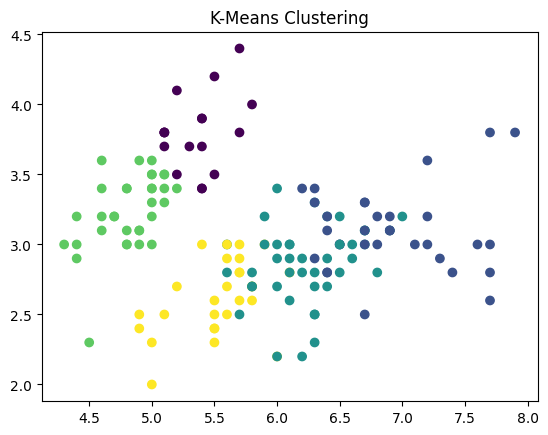

In [ ]:
## a) K-Means Clustering
kmeans = KMeans(n_clusters=5)
kmeans.fit(X)

# Visualization
plt.scatter(X[:, 0], X[:, 1], c=kmeans.labels_, cmap='viridis')
plt.title("K-Means Clustering")
plt.show()

#HomeWork

### Introduction to the Wine Quality Dataset


In this exercise, we will explore the Wine Quality dataset, which contains information about various wine samples and their quality ratings. We will learn how to visualize the data and train a simple machine learning model to classify the quality of the wines based on their features.


## Load the Required Libraries


In the next cell, you will load the necessary libraries. Run the code below to import the libraries we need for our analysis.


In [5]:
# Load the required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC


##Load the Wine Quality Dataset

##Load the Wine Quality Dataset
Now, we will load the Wine Quality dataset.


In [ ]:
# Load the Wine Quality dataset
wine = datasets.load_wine()
X = wine.data  # Features
y = wine.target  # Target variable (wine quality)

# Create a DataFrame for better visualization
wine_df = pd.DataFrame(X, columns=wine.feature_names)
wine_df['target'] = y

# Display the feature names
print("Feature names:", wine.feature_names)
# Display the first few rows of the dataset
wine_df.head()


Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


##Part1:Visualize the Data

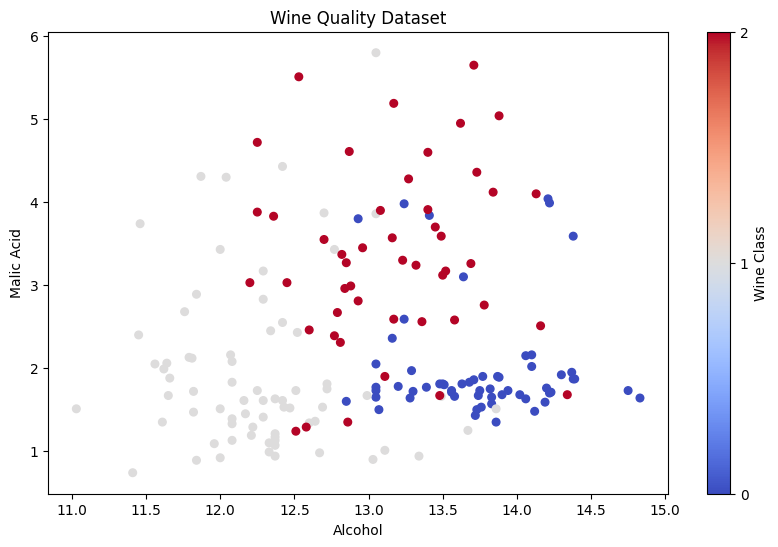

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets

# Ensure wine_df is defined
try:
    wine_df
except NameError:
    wine = datasets.load_wine()
    wine_df = pd.DataFrame(wine.data, columns=wine.feature_names)
    wine_df['target'] = wine.target
    y = wine.target

# Visualize the Wine dataset using Alcohol and Malic Acid
plt.figure(figsize=(10, 6))

# Each dot represents one wine sample
plt.scatter(
    wine_df['alcohol'],
    wine_df['malic_acid'],
    c=wine_df['target'],
    cmap='coolwarm',
    s=30
)

# Add the title and axis labels
plt.title("Wine Quality Dataset")
plt.xlabel("Alcohol")
plt.ylabel("Malic Acid")

# Show the three wine classes
plt.colorbar(ticks=np.unique(wine_df['target']), label='Wine Class')

plt.show()

### Wine Dataset Visualization Results

The scatter plot compares alcohol content and malic acid concentration across three wine classes. Each point represents a wine sample, and the colors indicate its class. The graph shows some separation between the classes, although several samples overlap. This suggests that alcohol and malic acid are useful features for classification, but additional chemical measurements may improve the accuracy of predictions.

## Additional Dataset Analysis: Breast Cancer Wisconsin

In [1]:
# Load a new biological dataset for classification
from sklearn.datasets import load_breast_cancer
import pandas as pd

# Load the Breast Cancer Wisconsin dataset
cancer = load_breast_cancer()

# Separate the measurements and classification labels
X_cancer = cancer.data
y_cancer = cancer.target

# Display basic information about the dataset
print("Dataset:", "Breast Cancer Wisconsin")
print("Number of samples:", X_cancer.shape[0])
print("Number of features:", X_cancer.shape[1])
print("Classes:", cancer.target_names)

# Display the first five samples
cancer_df = pd.DataFrame(
    X_cancer,
    columns=cancer.feature_names
)

display(cancer_df.head())

Dataset: Breast Cancer Wisconsin
Number of samples: 569
Number of features: 30
Classes: ['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [8]:
from sklearn.model_selection import train_test_split

# Split cancer_df into features (X) and target (y)
X_cancer_df = cancer_df.drop(columns=['Diagnosis']) if 'Diagnosis' in cancer_df.columns else cancer_df
y_cancer_df = cancer_plot_df['Diagnosis'] if 'Diagnosis' in cancer_plot_df.columns else y_cancer

# Split into training and test sets (70% train, 30% test)
X_train_df, X_test_df, y_train_df, y_test_df = train_test_split(
    X_cancer_df,
    y_cancer_df,
    test_size=0.3,
    random_state=42,
    stratify=y_cancer_df
)

print(f"Training set shape: {X_train_df.shape}")
print(f"Test set shape: {X_test_df.shape}")

Training set shape: (398, 30)
Test set shape: (171, 30)


In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Standardize the features for the cancer_df dataset splits
scaler_df = StandardScaler()
X_train_df_scaled = scaler_df.fit_transform(X_train_df)
X_test_df_scaled = scaler_df.transform(X_test_df)

# Initialize and train the SVM classifier
svm_df_model = SVC(kernel='linear', random_state=42)
svm_df_model.fit(X_train_df_scaled, y_train_df)

# Evaluate the trained model on the scaled test set
y_pred_df = svm_df_model.predict(X_test_df_scaled)
accuracy_df = accuracy_score(y_test_df, y_pred_df)

print(f"SVM Model trained successfully on the new cancer_df training set!")
print(f"Test Set Accuracy: {accuracy_df * 100:.2f}%")

SVM Model trained successfully on the new cancer_df training set!
Test Set Accuracy: 98.25%


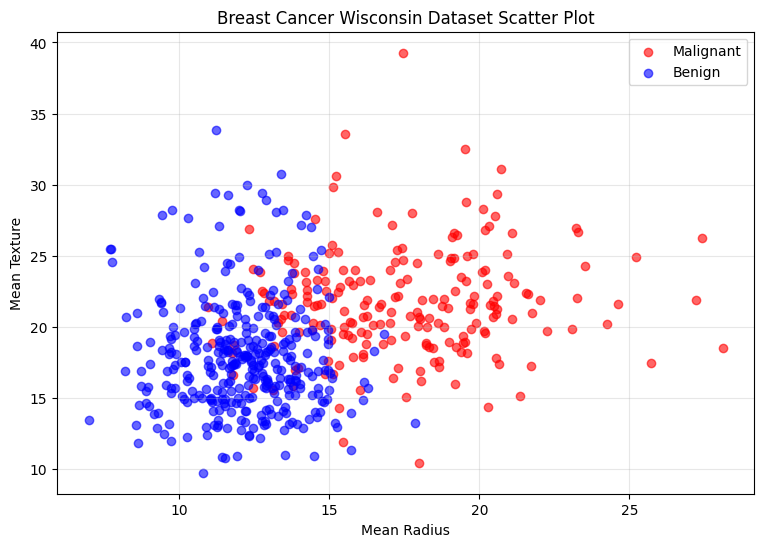

In [6]:

# Create a scatter plot for the Breast Cancer Wisconsin dataset
import matplotlib.pyplot as plt
import pandas as pd

# Create a DataFrame with the dataset features
cancer_plot_df = pd.DataFrame(
    X_cancer,
    columns=cancer.feature_names
)

# Add the classification labels
cancer_plot_df["Diagnosis"] = y_cancer

# Create the scatter plot
plt.figure(figsize=(9, 6))

# Plot malignant samples (class 0)
plt.scatter(
    cancer_plot_df[cancer_plot_df["Diagnosis"] == 0]["mean radius"],
    cancer_plot_df[cancer_plot_df["Diagnosis"] == 0]["mean texture"],
    label="Malignant",
    color="red",
    alpha=0.6
)

# Plot benign samples (class 1)
plt.scatter(
    cancer_plot_df[cancer_plot_df["Diagnosis"] == 1]["mean radius"],
    cancer_plot_df[cancer_plot_df["Diagnosis"] == 1]["mean texture"],
    label="Benign",
    color="blue",
    alpha=0.6
)

# Add graph labels
plt.title("Breast Cancer Wisconsin Dataset Scatter Plot")
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.legend()
plt.grid(alpha=0.3)

# Save the scatter plot
plt.savefig(
    "breast_cancer_scatter_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Breast Cancer Wisconsin Scatter Plot Interpretation

The scatter plot illustrates the relationship between mean radius and mean texture for malignant and benign breast tissue samples. The red dots represent malignant samples, while the blue dots represent benign samples. Malignant samples generally have higher mean radius values, whereas benign samples are more concentrated at lower mean radius values. However, some overlap exists between the two groups, indicating that these two features alone cannot perfectly distinguish malignant from benign samples.

This visualization demonstrates how biological measurements can reveal patterns within a dataset. It also highlights the importance of using multiple features in machine-learning classification to improve predictive accuracy.


In [2]:

# Import tools for splitting and scaling the dataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split the dataset: 70% training and 30% testing
X_train_cancer, X_test_cancer, y_train_cancer, y_test_cancer = train_test_split(
    X_cancer,
    y_cancer,
    test_size=0.30,
    random_state=42,
    stratify=y_cancer
)

# Standardize the features using only the training data
scaler_cancer = StandardScaler()

X_train_cancer_scaled = scaler_cancer.fit_transform(X_train_cancer)
X_test_cancer_scaled = scaler_cancer.transform(X_test_cancer)

# Display the number of samples in each group
print("Training samples:", X_train_cancer.shape[0])
print("Testing samples:", X_test_cancer.shape[0])
print("Data preprocessing completed successfully!")

Training samples: 398
Testing samples: 171
Data preprocessing completed successfully!


In [3]:

# Import classification models and evaluation tools
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Create the three classification models
svm_cancer = SVC(random_state=42)
tree_cancer = DecisionTreeClassifier(random_state=42)
logistic_cancer = LogisticRegression(max_iter=1000, random_state=42)

# Train the models using the training dataset
svm_cancer.fit(X_train_cancer_scaled, y_train_cancer)
tree_cancer.fit(X_train_cancer, y_train_cancer)
logistic_cancer.fit(X_train_cancer_scaled, y_train_cancer)

# Make predictions using the testing dataset
svm_predictions = svm_cancer.predict(X_test_cancer_scaled)
tree_predictions = tree_cancer.predict(X_test_cancer)
logistic_predictions = logistic_cancer.predict(X_test_cancer_scaled)

# Calculate the classification accuracy for each model
svm_accuracy = accuracy_score(y_test_cancer, svm_predictions)
tree_accuracy = accuracy_score(y_test_cancer, tree_predictions)
logistic_accuracy = accuracy_score(y_test_cancer, logistic_predictions)

# Display the results
print("Breast Cancer Wisconsin Classification Results")
print(f"SVM Accuracy: {svm_accuracy * 100:.2f}%")
print(f"Decision Tree Accuracy: {tree_accuracy * 100:.2f}%")
print(f"Logistic Regression Accuracy: {logistic_accuracy * 100:.2f}%")

Breast Cancer Wisconsin Classification Results
SVM Accuracy: 97.66%
Decision Tree Accuracy: 91.81%
Logistic Regression Accuracy: 98.83%


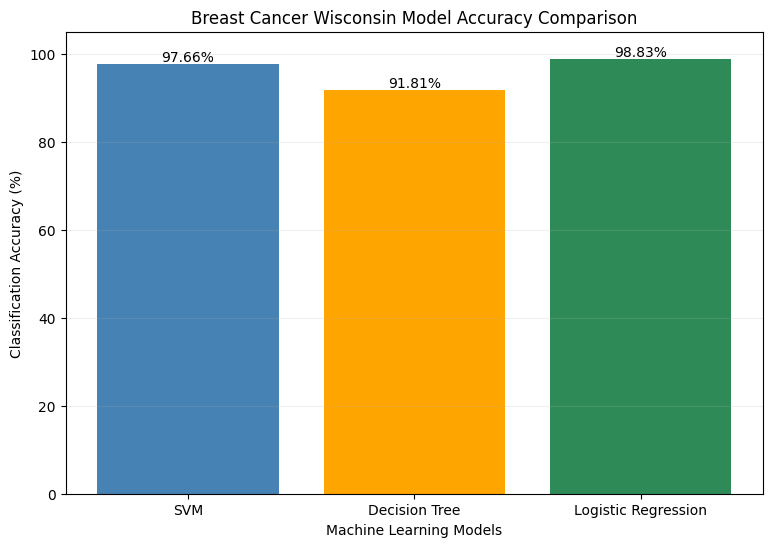

In [4]:

# Import the plotting library
import matplotlib.pyplot as plt

# Model names and their calculated accuracies
model_names = ["SVM", "Decision Tree", "Logistic Regression"]
model_accuracies = [
    svm_accuracy * 100,
    tree_accuracy * 100,
    logistic_accuracy * 100
]

# Create a bar graph comparing model performance
plt.figure(figsize=(9, 6))
bars = plt.bar(
    model_names,
    model_accuracies,
    color=["steelblue", "orange", "seagreen"]
)

# Add accuracy percentages above each bar
for bar, accuracy in zip(bars, model_accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{accuracy:.2f}%",
        ha="center"
    )

# Label the graph
plt.title("Breast Cancer Wisconsin Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Classification Accuracy (%)")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.2)

# Save the graph for your GitHub repository
plt.savefig(
    "breast_cancer_model_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Interpretation of Breast Cancer Wisconsin Classification Results

The Breast Cancer Wisconsin dataset was used to evaluate the performance of three machine-learning classification models: Support Vector Machine (SVM), Decision Tree, and Logistic Regression. The dataset contained 569 samples with 30 features describing characteristics of cell nuclei. The data was divided into 70% training and 30% testing to evaluate each model's ability to classify samples as malignant or benign.

The results showed that Logistic Regression achieved the highest classification accuracy at **98.83%**, followed by SVM at **97.66%** and Decision Tree at **91.81%**. These findings suggest that Logistic Regression performed best on this particular dataset and testing split. Although all three models demonstrated strong performance, the Decision Tree produced more classification errors than the other two models.

Overall, this analysis demonstrates how machine-learning algorithms can be applied to biological data to identify patterns and classify samples. The comparison also highlights the importance of evaluating multiple models because their performance can vary depending on the dataset. These results are based on a held-out test set and do not establish clinical diagnostic reliability.


## Standardize the Features


Before training our model, we need to standardize the features. Run the code below to standardize the features.

In [2]:
from sklearn.datasets import load_breast_cancer

# Ensure the Breast Cancer Wisconsin features are loaded
try:
    X2 = X_cancer
except NameError:
    cancer_temp = load_breast_cancer()
    X2 = cancer_temp.data

## Part2: Split the Data



In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_breast_cancer

# Ensure the Breast Cancer Wisconsin features and labels are loaded
try:
    X2 = X_cancer
    y2 = y_cancer
except NameError:
    cancer_temp = load_breast_cancer()
    X2 = cancer_temp.data
    y2 = cancer_temp.target

# Split the dataset into 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X2,
    y2,
    test_size=0.30,
    random_state=42,
    stratify=y2
)

# Standardize the features using only the training data
scaler = StandardScaler()

# Fit the scaler on training data
X_train = scaler.fit_transform(X_train)

# Apply the same scaling to testing data
X_test = scaler.transform(X_test)

print("Breast Cancer Wisconsin data prepared successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Breast Cancer Wisconsin data prepared successfully!
Training samples: 398
Testing samples: 171


## Part 3 : Create Support Vector Machine (SVM), Decision Tree, and Logistic Regression models to classify breast tissue samples as malignant or benign using the Breast Cancer Wisconsin dataset. Evaluate and compare the accuracy of each model

###SVM

#### Train the SVM Model

In [6]:
from sklearn.svm import SVC

svm = SVC(kernel='linear')
svm.fit(X_train, y_train)

SVC(kernel='linear')

####make prediction

In [7]:
y_pred = svm.predict(X_test)

#### Evaluate the Model



Now that we have trained our model, we can evaluate its performance on the test set. Run the code below to make predictions and calculate the accuracy.

In [8]:
from sklearn.metrics import accuracy_score

# Make predictions and calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy of the SVM model: {accuracy:.2f}")

Accuracy of the SVM model: 0.98



### SVM Classification Results

The Support Vector Machine (SVM) model achieved an accuracy of approximately 98% on the Breast Cancer Wisconsin testing dataset. This indicates that the model correctly classified approximately 98% of the breast tissue samples as malignant or benign using measurements of cell nuclei. The results demonstrate that a linear SVM can effectively identify patterns within this biological dataset. However, classification accuracy alone does not establish whether the model is suitable for clinical diagnosis.


### Decision Tree model

In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Train the Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Make predictions
y_pred_dt = dt_model.predict(X_test)

# Evaluate the model
accuracy_dt = accuracy_score(y_test, y_pred_dt)
print(f"Accuracy of the Decision Tree model: {accuracy_dt:.2f}")

Accuracy of the Decision Tree model: 0.92



### Decision Tree Classification Results

The Decision Tree model was used to classify breast tissue samples as malignant or benign using the Breast Cancer Wisconsin dataset. The model achieved approximately 92% accuracy on the testing dataset, indicating that it correctly classified most samples based on their cell nuclei measurements.

Compared with the SVM model, which achieved approximately 98% accuracy, the Decision Tree demonstrated lower classification performance. This suggests that the SVM model was more effective for this particular dataset and training/testing split. However, both models demonstrated the ability to identify patterns within biological measurements.


###Logistic Regression

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Train the Logistic Regression model
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_test)

# Evaluate the model
accuracy_lr = accuracy_score(y_test, y_pred_lr)
print(f"Accuracy of the Logistic Regression model: {accuracy_lr:.2f}")

Accuracy of the Logistic Regression model: 0.99


### Logistic Regression Classification Results

The Logistic Regression model achieved approximately 99% accuracy on the Breast Cancer Wisconsin testing dataset. This indicates that the model correctly classified approximately 99% of the breast tissue samples as malignant or benign based on their cell nuclei measurements. Logistic Regression demonstrated the highest classification accuracy compared to the SVM model, which achieved approximately 98%, and the Decision Tree model, which achieved approximately 92%. These results suggest that Logistic Regression was the most effective of the three models for this particular dataset and training/testing split. Overall, the findings demonstrate how machine-learning algorithms can identify patterns in biological data and distinguish between malignant and benign samples, although further validation would be necessary before considering clinical applications.

### Comparison of Machine Learning Models

Three classification models were evaluated using the Breast Cancer Wisconsin dataset: Support Vector Machine (SVM), Decision Tree, and Logistic Regression. Each model was trained using 70% of the dataset and evaluated using the remaining 30% to determine its ability to classify breast tissue samples as malignant or benign.

| Model | Accuracy |
|---|---|
| Support Vector Machine (SVM) | 98% |
| Decision Tree | 92% |
| Logistic Regression | **99%** |

### Interpretation of Results

The results showed that Logistic Regression achieved the highest classification accuracy at approximately 99%, followed by SVM at 98% and Decision Tree at 92%. All three models demonstrated strong classification performance, indicating that measurements of cell nuclei provide useful information for distinguishing malignant from benign breast tissue samples.

Logistic Regression was the most effective model for this particular training and testing split, while Decision Tree demonstrated the lowest accuracy. These findings highlight the importance of comparing different machine-learning algorithms when analyzing biological datasets. Although the models achieved high accuracy, additional evaluation would be necessary to determine their reliability in clinical applications.

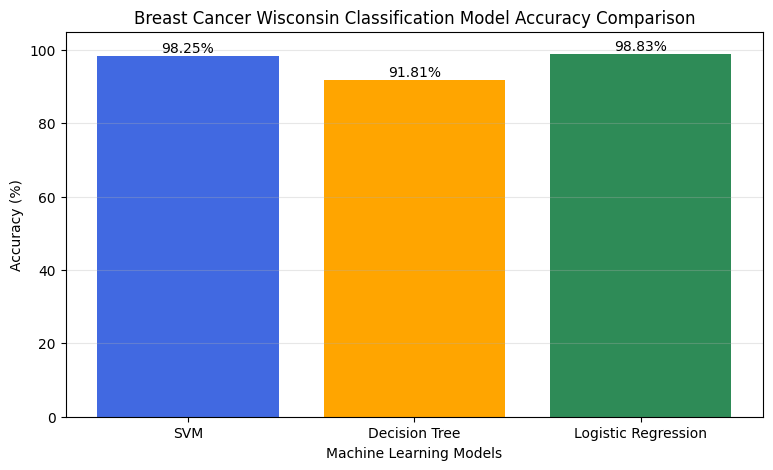

In [11]:


import matplotlib.pyplot as plt

# Names of the three classification models
models = ['SVM', 'Decision Tree', 'Logistic Regression']

# Convert Breast Cancer Wisconsin accuracy scores to percentages
accuracies = [accuracy * 100, accuracy_dt * 100, accuracy_lr * 100]

# Create the comparison graph
plt.figure(figsize=(9, 5))
bars = plt.bar(
    models,
    accuracies,
    color=['royalblue', 'orange', 'seagreen']
)

# Label the graph
plt.title('Breast Cancer Wisconsin Classification Model Accuracy Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 105)

# Display accuracy values above each bar
for bar, score in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 1,
        f'{score:.2f}%',
        ha='center'
    )

# Add grid lines
plt.grid(axis='y', alpha=0.3)

# Save the graph for GitHub
plt.savefig(
    'breast_cancer_model_accuracy_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

# Display the graph
plt.show()

### Final Results and Data Preparation

The Breast Cancer Wisconsin dataset was used to evaluate three machine-learning classification models: Support Vector Machine (SVM), Decision Tree, and Logistic Regression. The dataset contained 569 samples with 30 features describing characteristics of cell nuclei. The data was divided into 70% training (398 samples) and 30% testing (171 samples). Standardization was performed using only the training data, and the same scaling was applied to the testing data to prevent data leakage.

After preprocessing, the SVM model achieved an accuracy of **98.25%**, the Decision Tree achieved **91.81%**, and Logistic Regression achieved **98.83%**. Logistic Regression demonstrated the highest classification accuracy, followed closely by SVM, while Decision Tree had the lowest accuracy.

These results indicate that all three models performed well in classifying breast tissue samples as malignant or benign based on their cell nuclei measurements. The findings suggest that Logistic Regression was the most effective model for this particular dataset and training/testing split. Overall, this exercise demonstrates how machine-learning algorithms can analyze biological data and identify patterns that distinguish different sample classifications. However, additional validation would be necessary before applying these models in a clinical setting.